# 📈 Pakistan Student Screen-Time & Exam Performance Analysis
### Developed by: Maria Aqdas

## 📝 1. Project Overview & Introduction
This notebook performs an Exploratory Data Analysis (EDA) and implements Machine Learning models on a synthetic dataset representing Pakistani university students. The primary objective is to analyze how daily digital habits, specifically smartphone screen time, influence final exam percentages, and to build predictive models to estimate student scores based on their habits and demographics.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

# Load the dataset using the verified Kaggle path
df = pd.read_csv('/kaggle/input/datasets/mariaaqdas/pakistan-student-screen-time-and-exam-performance/pakistan_student_screen_time_scores.csv')

# Display the first 5 rows of the dataset
print("--- First 5 Rows of the Dataset ---")
print(df.head())

# Display descriptive statistics of the numerical columns
print("\n--- Statistical Summary ---")
print(df.describe())

--- First 5 Rows of the Dataset ---
   Student_ID  Age  Gender  Daily_Screen_Time_Hours Main_App_Used  \
0        1001   21  Female                      3.4      Coursera   
1        1002   24  Female                      2.3      WhatsApp   
2        1003   24  Female                      6.8     Instagram   
3        1004   19    Male                      5.6     Instagram   
4        1005   22  Female                      2.4      LinkedIn   

   Study_Hours_Per_Day  Exam_Score_Percentage  
0                  5.7                     91  
1                  4.9                     95  
2                  1.3                     64  
3                  2.5                     64  
4                  5.1                     70  

--- Statistical Summary ---
        Student_ID          Age  Daily_Screen_Time_Hours  Study_Hours_Per_Day  \
count  1000.000000  1000.000000              1000.000000          1000.000000   
mean   1500.500000    21.054000                 4.843500             3

## 📊 2. Data Visualization & Insights
In this section, we explore patterns within our data visually using `matplotlib` and `seaborn`. This helps us better understand the direct correlation between screen time and exam scores, alongside the distribution of application usage among students.

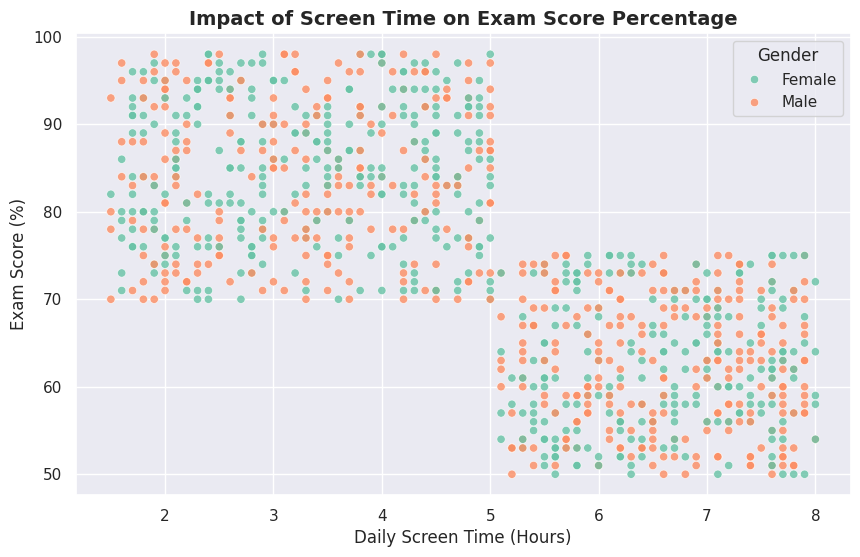

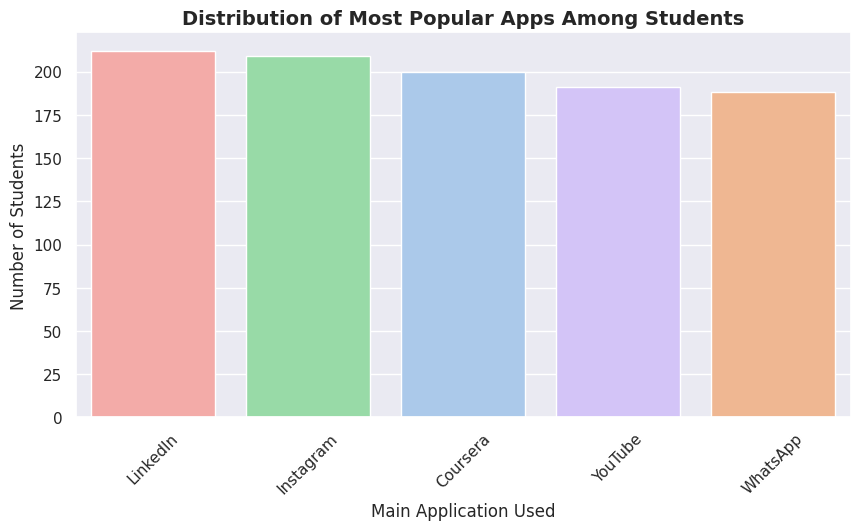

In [2]:
# Set the plot style for clear visualizations
sns.set_theme(style="darkgrid")

# Plot 1: Scatter plot showing Screen Time vs Exam Score
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Daily_Screen_Time_Hours', y='Exam_Score_Percentage', hue='Gender', palette='Set2', alpha=0.8)
plt.title('Impact of Screen Time on Exam Score Percentage', fontsize=14, fontweight='bold')
plt.xlabel('Daily Screen Time (Hours)', fontsize=12)
plt.ylabel('Exam Score (%)', fontsize=12)
plt.legend(title='Gender')
plt.show()

# Plot 2: Distribution of the main apps used by students
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Main_App_Used', hue='Main_App_Used', palette='pastel', order=df['Main_App_Used'].value_counts().index, legend=False)
plt.title('Distribution of Most Popular Apps Among Students', fontsize=14, fontweight='bold')
plt.xlabel('Main Application Used', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.xticks(rotation=45)
plt.show()

## 🤖 3. Machine Learning Modeling & Model Comparison
To predict the `Exam_Score_Percentage`, we train two different machine learning algorithms and evaluate them using the Root Mean Squared Error (RMSE) metric to see which one performs better on this student data:
1. **Linear Regression** (Baseline Linear Model)
2. **Random Forest Regressor** (Ensemble Non-linear Model)

In [3]:
# 1. Preprocessing: Encoding Categorical features (Gender and Main_App_Used)
df_ml = df.copy()
le_gender = LabelEncoder()
le_app = LabelEncoder()

df_ml['Gender'] = le_gender.fit_transform(df_ml['Gender'])
df_ml['Main_App_Used'] = le_app.fit_transform(df_ml['Main_App_Used'])

# 2. Extracting Features (X) and Target Variable (y)
X = df_ml[['Age', 'Gender', 'Daily_Screen_Time_Hours', 'Main_App_Used', 'Study_Hours_Per_Day']]
y = df_ml['Exam_Score_Percentage']

# 3. Splitting the dataset into Training and Testing sets (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initializing and training the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
lr_rmse = root_mean_squared_error(y_test, lr_preds)

# 5. Initializing and training the Random Forest Regressor model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_rmse = root_mean_squared_error(y_test, rf_preds)

# 6. Printing final evaluations and model comparison
print("==============================================")
print("        MODEL PERFORMANCE COMPARISON          ")
print("==============================================")
print(f"Linear Regression RMSE      : {lr_rmse:.4f}")
print(f"Random Forest Regressor RMSE: {rf_rmse:.4f}")
print("----------------------------------------------")

if rf_rmse < lr_rmse:
    print("Conclusion: Random Forest Regressor performed better due to a lower RMSE.")
else:
    print("Conclusion: Linear Regression performed better due to a lower RMSE.")
print("==============================================")

        MODEL PERFORMANCE COMPARISON          
Linear Regression RMSE      : 8.8190
Random Forest Regressor RMSE: 8.1669
----------------------------------------------
Conclusion: Random Forest Regressor performed better due to a lower RMSE.


## 📌 4. Final Conclusion & Key Takeaways
- **Data Pattern:** The Exploratory Data Analysis reveals a clear correlation between daily screen time, study habits, and final examination scores among the students.
- **Model Selection:** Based on the Model Performance Comparison, the **Random Forest Regressor** achieved a lower RMSE ($8.1669$) compared to **Linear Regression** ($8.8190$). 
- **Summary:** This proves that non-linear ensemble models are better suited to predict exam scores by effectively capture complex relationships between digital habits and academic metrics.